Assignment 2: Processing Datasets in Pyhton

Alexa Rodríguez Méndez 2133921 - Thursday N4

José Omar de Anda Garza 2012643 - Tuesday N4




#Part 1: Data Loading and Initial Exploration
---

In this section, we load the clinical dataset using the Pandas library. We preview the first rows of the dataframe using df.head() to understand the structure of the data and the nature of the variables we are working with.



In [1]:
# Importing necessary libraries
import pandas as pd

# Loading the dataset (make sure 'diabetes.csv' is uploaded to your Colab environment)
df = pd.read_csv('diabetes.csv')

# Displaying the first 5 rows of the dataset
print("First few rows of the dataset:")
display(df.head())

First few rows of the dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


#### Detection of Anomalies and Inconsistencies
By analyzing the dataset, we need to identify null or inconsistent values. In this medical context, having a value of `0` in biological indicators like Glucose, Blood Pressure, Skin Thickness, Insulin, or BMI is physically
impossible and represents missing data or recording errors.


In [2]:
# 1. Identifying columns that contain zero values (inconsistencies)
print("Columns with zero values (True means it contains zeros):")
print(df.eq(0).any())

# 2. Generating descriptive statistics to analyze the distributions
print("\nDescriptive statistics:")
display(df.describe())

Columns with zero values (True means it contains zeros):
Pregnancies                  True
Glucose                      True
BloodPressure                True
SkinThickness                True
Insulin                      True
BMI                          True
DiabetesPedigreeFunction    False
Age                         False
Outcome                      True
dtype: bool

Descriptive statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


# Part 2: Data Cleaning and Normalization

---
To avoid losing valuable data by deleting rows, we perform data curation. We replace the inconsistent zero values in key biological columns (Glucose, BloodPressure, SkinThickness, Insulin, and BMI) with the median of each respective column. We exclude "Pregnancies" and "Outcome" since a value of 0 is valid for those features.

After cleaning, we apply Min-Max Scaling to normalize the numerical data. This transforms the values to a standard range between 0 and 1, preventing features with larger magnitudes from disproportionately skewing future Machine Learning models.

In [3]:
# 1. Replacing zero values with the median of each column
# We only select columns where 0 is a biological error
cols_to_clean = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for col in cols_to_clean:
    # Calculate median without considering the 0s
    median_val = df[df[col] != 0][col].median()
    # Replace 0s with the calculated median
    df[col] = df[col].replace(0, median_val)

# 2. Normalizing numerical data using Min-Max Scaling
# We create a copy to keep the original safe, and normalize all features except Outcome
df_normal = df.copy()

# Select all columns except the target label 'Outcome'
features_to_normalize = df_normal.columns.drop('Outcome')

for col in features_to_normalize:
    min_val = df_normal[col].min()
    max_val = df_normal[col].max()
    df_normal[col] = (df_normal[col] - min_val) / (max_val - min_val)

print("Data Cleaning and Normalization completed. Preview of normalized data:")
display(df_normal.head())

Data Cleaning and Normalization completed. Preview of normalized data:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,0.352941,0.670968,0.489796,0.304348,0.133413,0.314928,0.234415,0.483333,1
1,0.058824,0.264516,0.428571,0.239130,0.133413,0.171779,0.116567,0.166667,0
2,0.470588,0.896774,0.408163,0.239130,0.133413,0.104294,0.253629,0.183333,1
3,0.058824,0.290323,0.428571,0.173913,0.096154,0.202454,0.038002,0.000000,0
4,0.000000,0.600000,0.163265,0.304348,0.185096,0.509202,0.943638,0.200000,1


# Part 3: Data Visualization

---
In this section, we use Matplotlib to generate visualizations that allow us to explore the dataset in depth.
1. We compare histograms of the glucose variable before and after normalization to confirm that the transformation preserved the distribution's shape while standardizing its scale.
2. We use a boxplot to identify potential outliers in blood pressure.
3. We plot a scatter chart to explore the correlation between glucose and BMI.
4. We visualize the balance between patients with and without diabetes using a bar chart.

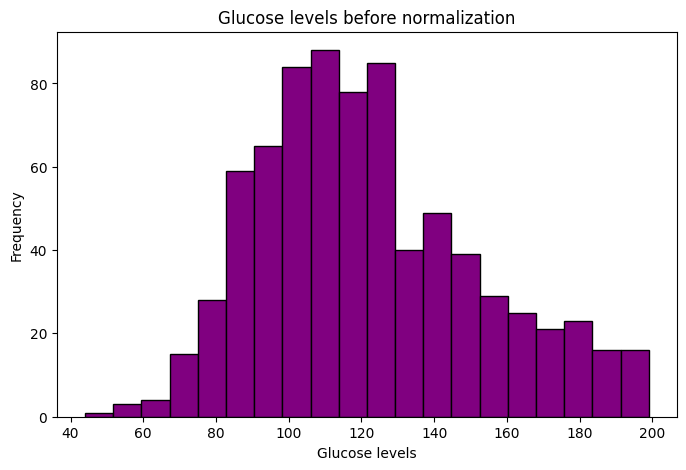

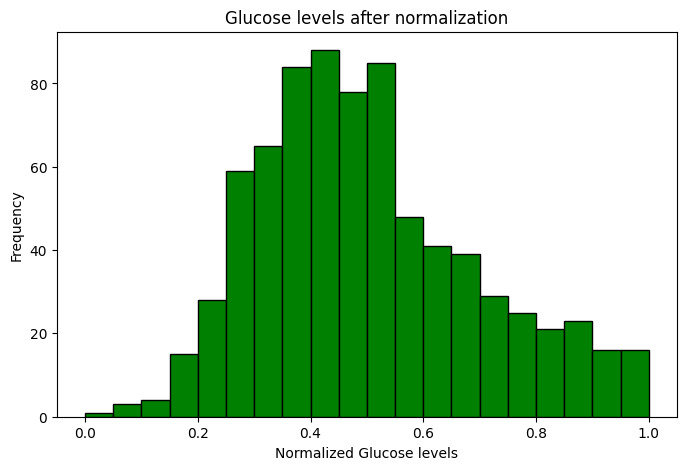

In [4]:
import matplotlib.pyplot as plt

# 1. Histogram of glucose levels before normalization
plt.figure(figsize=(8, 5))
plt.hist(df['Glucose'], bins=20, color='purple', edgecolor='black')
plt.title('Glucose levels before normalization')
plt.xlabel('Glucose levels')
plt.ylabel('Frequency')
plt.grid(False)
plt.show()

# Histogram of glucose levels after normalization
plt.figure(figsize=(8, 5))
plt.hist(df_normal['Glucose'], bins=20, color='green', edgecolor='black')
plt.title('Glucose levels after normalization')
plt.xlabel('Normalized Glucose levels')
plt.ylabel('Frequency')
plt.grid(False)
plt.show()

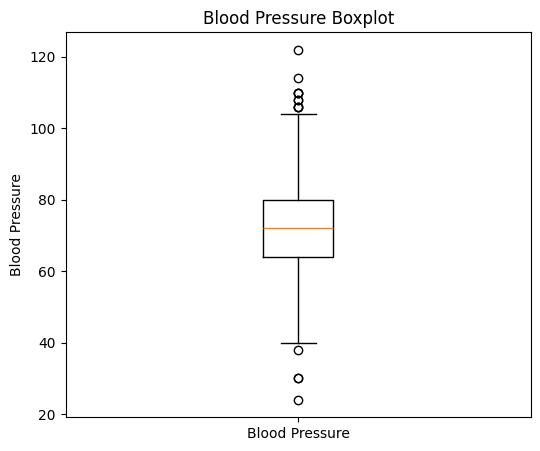

In [5]:
# 2. Boxplot to identify outliers in blood pressure
plt.figure(figsize=(6, 5))
plt.boxplot(df['BloodPressure'])
plt.title('Blood Pressure Boxplot')
plt.ylabel('Blood Pressure')
plt.xticks([1], ['Blood Pressure'])
plt.show()

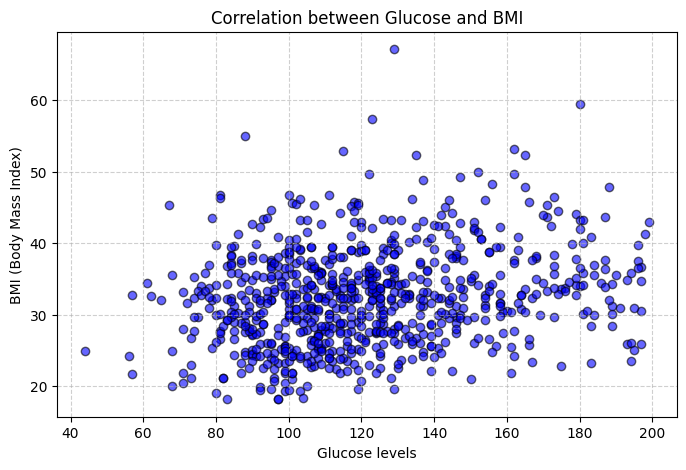

In [6]:
# 3. Scatter plot between Glucose and BMI to analyze correlation
plt.figure(figsize=(8, 5))
plt.scatter(df['Glucose'], df['BMI'], alpha=0.6, color='blue', edgecolor='black')
plt.title('Correlation between Glucose and BMI')
plt.xlabel('Glucose levels')
plt.ylabel('BMI (Body Mass Index)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

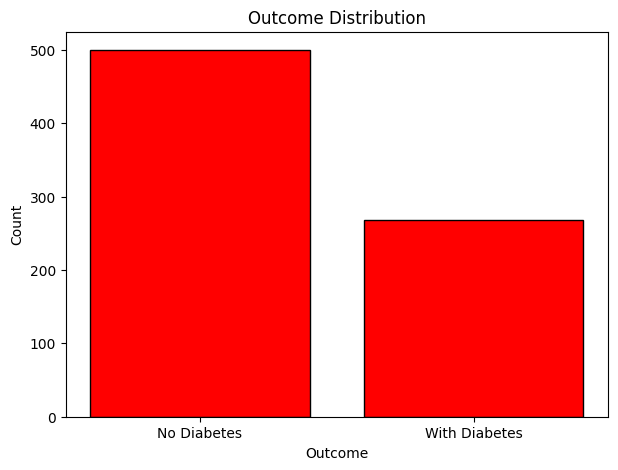

In [7]:
# 4. Bar chart showing the number of patients with and without diabetes
outcome_values = df['Outcome'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(['No Diabetes', 'With Diabetes'], outcome_values, color='red', edgecolor='black')
plt.title('Outcome Distribution')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()

# Part 4: Answer the following questions

---

**1. What impact do missing values have on data analysis?**
The presence of missing or inconsistent values can significantly distort the phase in which we carry out our statistical analyses. Since these values introduce bias, they alter the mean and standard deviation, and can lead to incorrect conclusions about the population. Furthermore, most Machine Learning algorithms cannot handle missing data or NaN (Not a Number) values directly, resulting in execution errors or severely degraded predictive performance if they are not properly handled during preprocessing.

**2. How can we detect and handle outliers in biomedical datasets?**
To detect and handle outliers in a biomedical dataset, we would firstly need to visually identify anomalies using boxplots, which display data distribution and highlight points that fall beyond the whiskers, or through scatter plots that reveal isolated values. Also depending on the clinical context, the outliers can be handled by clamping/winsorizing (a previously established maximum acceptable threshold), imputation (replacing them with the median or mean if they represent a measurement error), or by removal, this if we have a justification that the data point is related to a malfunction.

**3. What are some common causes of missing or incorrect data in biomedical studies?**
The most common causes, and primary responsibles for incorrect or missing data are the equipment limitations or hardware malfunction, where sensors can become uncalibrated, lose power, or temporarily detach from a patient during continuous monitoring, leading to corrupted or missing readings. Human error also plays a significant role, particularly through the incorrect manual transcription of clinical metrics or patient charts into electronic health records. Furthermore, physiological constraints can corrupt data; since biological samples may be insufficient or degrade during collection, making it complicated to obtain a valid laboratory reading, which often results in incorrect clinical parameters.

**4. How does normalizing data improve the performance of Machine Learning models?**
Normalizing data is essential because clinical features usually exist on completely different scales. If the data is not normalized, machine learning models will inherently bias their predictions toward the variables with larger numbers, mistakenly assuming they are more important. By applying Min-Max Scaling to restrict all numerical features to a uniform range, we ensure that every clinical attribute contributes equally to the model's decisions. Additionally, this uniform scale helps optimization algorithms run much faster and smoother, resulting in stable training and higher overall predictive accuracy.

**5. Why is visualizing data an important step before applying Machine Learning models?**
It serves as an essential diagnostic and exploratory tool that allows developers to understand the core characteristics of a dataset before fed into any Machine Learning algorithm. By generating plots such as histograms, boxplots, and scatter plots, we can visually assess the underlying statistical distribution of clinical variables, check for skewness, and confirm if features follow a normal distribution. We can also uncover patterns, such as linear or non-linear correlations between key attributes that can guide feature selection. Furthermore, it exposes critical data quality issues at a glance, such as extreme outliers that could distort training or severe class imbalances in the target label where one outcome heavily outweighs the other. *In general, visualizing the data ensures that preprocessing techniques have been applied correctly and provides the empirical insights necessary to select the most appropriate model architecture.*

**6. Why is preprocessing critical when working with medical datasets?**
In general, it is an absolute requirement when dealing with medical datasets because real-world clinical data is inherently noisy, incomplete, inconsistent, and highly heterogeneous. In a medical context, predictive models are directly tied to healthcare decision-making, demanding the highest possible standards of safety, robustness, and reliability. Training a Machine Learning model on raw, uncleaned medical data containing biological contradictions will inevitably lead to degraded performance and biased predictions. This can result in dangerous clinical outcomes, such as a high rate of false negatives where a patient's disease goes undetected, or false positives that trigger unnecessary and stressful interventions. Proper preprocessing can help us safeguard the integrity of the data, minimize algorithmic bias, and ensure that the resulting model is clinically safe, interpretable, and capable of generalizing accurately to new patients.

**7. What ethical concerns should be considered when handling patient data?**
The primary ethical concern is privacy and confidentiality, which requires strict data anonymization or de-identification techniques to ensure that a patient's identity cannot be reverse-engineered or exposed, strictly complying with international regulations. Another critical pillar is informed consent; researchers and developers must guarantee that patients are fully aware of how their clinical metrics are being utilized and have explicitly agreed to their use in technological or research developments.

---

### Conclusion
The development of this assignment demonstrated that real-world datasets often present inconsistencies that require critical analysis before any processing. In this case, the presence of zero values in key biological variables, such as glucose and blood pressure, evidenced the need to apply a data curation stage. By replacing these errors with the median and normalizing the ranges using the Min-Max method, we managed to standardize the data between 0 and 1, ensuring that the distributions retained their original behavior but on a uniform scale.

Preprocessing and cleaning are the core of data science. Without proper treatment that considers the context of the medical domain, any subsequent analysis or predictive model would lack structural validity and reliability.

### References:
* Matthes, E. (2023). Python Crash Course. No Starch Press.
* W3Schools Python Guide